## Random numbers with gaussian distribution: Metropolis algorithm

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def p_exp(x, sigma):
    esponente = -1 * x**2 / (2 * sigma**2)
    return np.exp(esponente)

def metropolis_algorithm(x, sigma, n, delta):
    step = []
    for i in range(n):

        random_delta = (np.random.rand() * 2*delta) - delta
        
        x_trial = x + random_delta

        w = p_exp(x_trial, sigma) / p_exp(x, sigma)

        if w >= 1:
            x = x_trial
            step.append(float(x))  
        else:
            r = np.random.rand()  
            if r <= w:
                x = x_trial
                step.append(float(x))
            else:
                step.append(float(x))

    return step

def autocorrelation(x, max_lag):
    
  n = len(x)
  mean_x = np.mean(x)
  var_x = np.var(x)  

  c = np.zeros(max_lag)
  for j in range(max_lag):

    cross_mean = np.mean(x[: n - j] * x[j:])

    c[j] = (cross_mean - mean_x**2) / var_x

  return c

In [3]:
ni = [100, 1000, 10000, 100000]
metropolis_n = []
for i in ni:    
    metropolis_n.append(metropolis_algorithm(0,1,i,5))

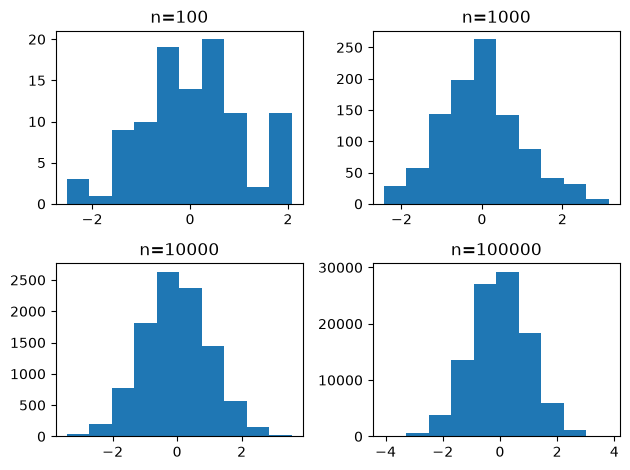

In [4]:
fig, ax = plt.subplots(2, 2)

for idx, a in enumerate(metropolis_n):
    
    current_ax = ax.flat[idx]
    current_ax.hist(a)
    current_ax.set_title(f'n={len(a)}')
    
plt.tight_layout()
plt.show()
    

In [5]:
delta = np.arange(1,11,1)

In [6]:
metropolis_delta = []

for i in delta:
    metropolis_delta.append(metropolis_algorithm(0, 1, 10000, i))

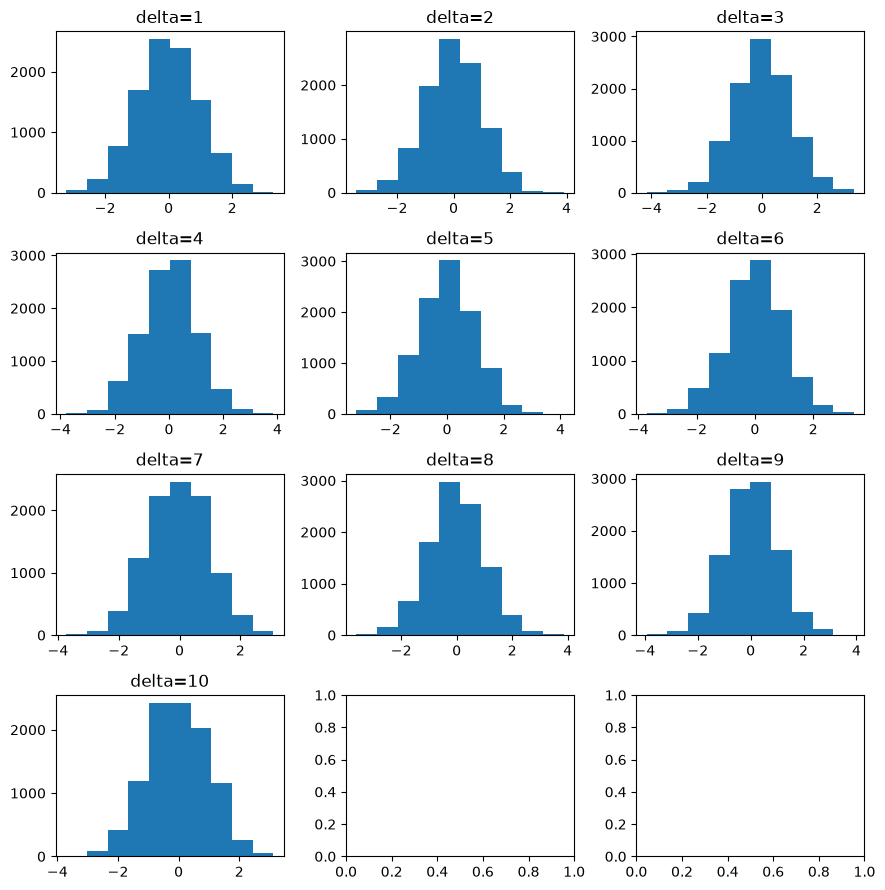

In [7]:
fig, ax = plt.subplots(4, 3, figsize=(9,9))

for idx, a in enumerate(metropolis_delta):
    
    current_ax = ax.flat[idx]
    current_ax.hist(a)
    current_ax.set_title(f'delta={delta[idx]}')
    
plt.tight_layout()
plt.show()

In [8]:
err_primo_momenta = []
err_second_momenta = []
ni = np.arange(100, 10000, 100)
metropolis_n = []

for i in ni:

    metro = metropolis_algorithm(0,1,i,5)
    metropolis_n.append(metro)
    err_primo_momenta.append(np.mean(metro))
    err_second_momenta.append(1-np.var(metro))

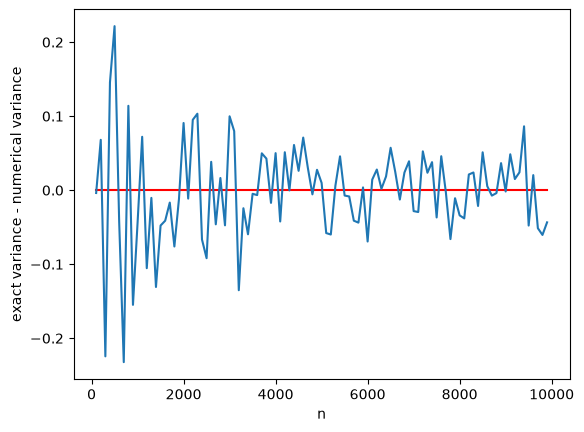

In [9]:
plt.plot(ni, ni*0, c='red')
plt.plot(ni, err_second_momenta)
plt.ylabel('exact variance - numerical variance')
plt.xlabel('n')
plt.show()

In [10]:
err_totale = []

for i in range(5):

    err_second_momenta = []
    ni = np.arange(100, 10000, 100)
    metropolis_n = []

    for i in ni:

        metro = metropolis_algorithm(0,1,i,5)
        metropolis_n.append(metro)
        err_second_momenta.append(1-np.var(metro))

    err_totale.append(err_second_momenta)
    
    

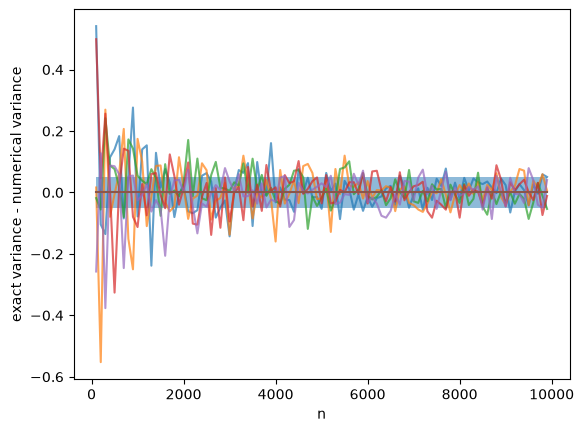

In [11]:
for i in err_totale:
    plt.plot(ni, i, alpha=0.7)   
plt.fill_between(ni, -0.05, 0.05, alpha=0.5)
plt.plot(ni, ni*0)
plt.ylabel('exact variance - numerical variance')
plt.xlabel('n')
plt.show()

## Correlations

In [12]:
metro = metropolis_algorithm(0,1,10000,5)
gauss = np.random.normal(size=10000)

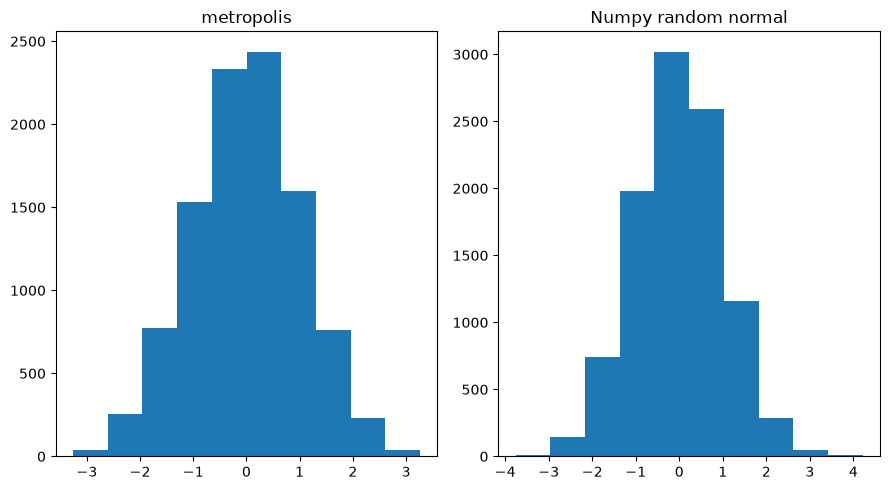

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(9,5))
ax[0].hist(metro)
ax[0].set_title('metropolis')
ax[1].hist(gauss)
ax[1].set_title('Numpy random normal')

plt.tight_layout()
plt.show()

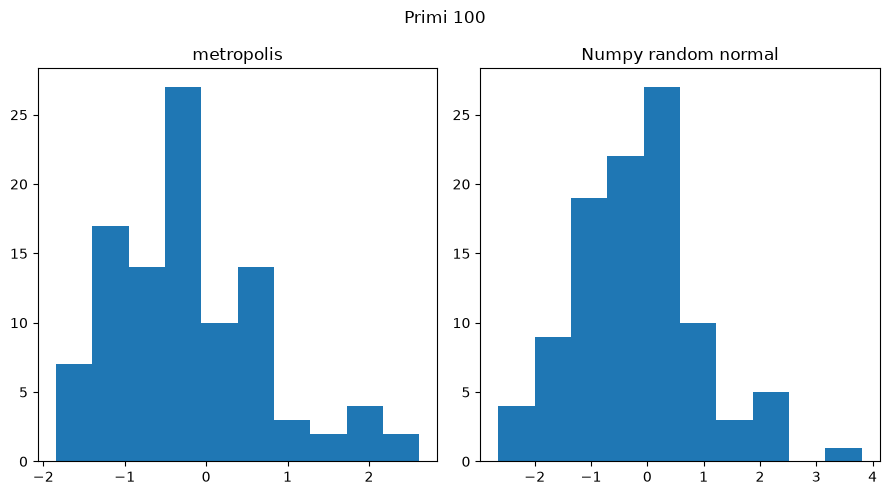

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(9,5))
ax[0].hist(metro[:100])
ax[0].set_title('metropolis')
ax[1].hist(gauss[:100])
ax[1].set_title('Numpy random normal')

plt.suptitle("Primi 100")
plt.tight_layout()
plt.show()

In [15]:
c_metro = autocorrelation(np.array(metro), 100)
c_gauss = autocorrelation(gauss, 100)

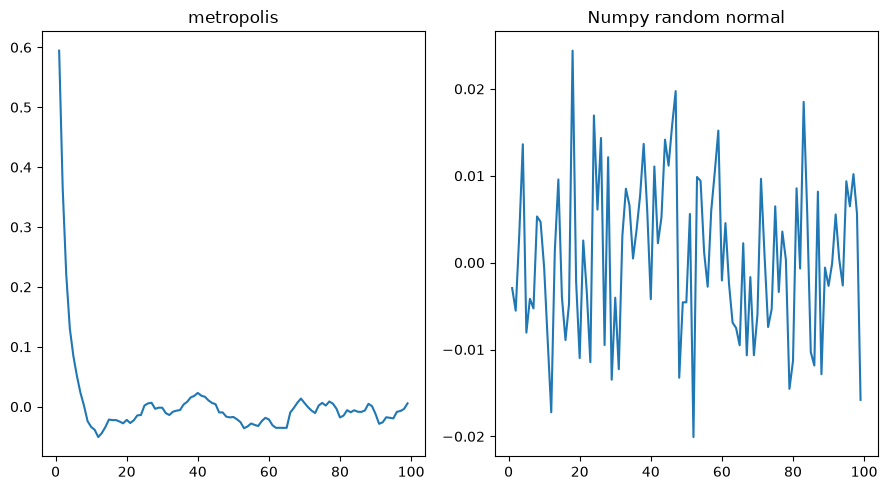

In [16]:
j = np.arange(1,100,1)

fig, ax = plt.subplots(1, 2, figsize=(9,5))
ax[0].plot(j, c_metro[1:100])
ax[0].set_title('metropolis')
ax[1].plot(j, c_gauss[1:100])
ax[1].set_title('Numpy random normal')

plt.tight_layout()
plt.show()

In [17]:
delta = [1, 5, 10, 25, 50]

metropolis_delta = []

for i in delta:
    metropolis_delta.append(metropolis_algorithm(0, 1, 10000, i))


In [18]:
c_metro = []

for i in metropolis_delta:

    c_metro.append(autocorrelation(np.array(i), 100))

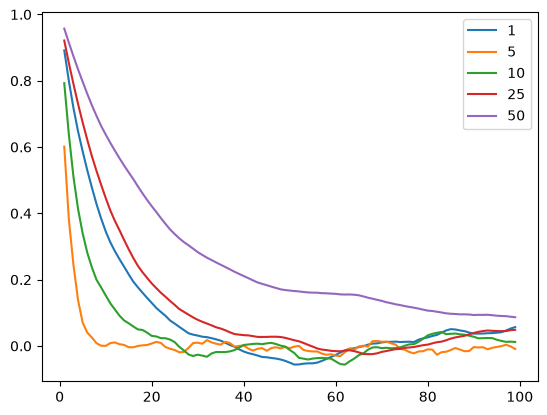

In [19]:
for i, c in enumerate(c_metro):

    plt.plot(j,c[1:100], label=delta[i])
plt.legend()
plt.show()